In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import numpy as  np

In [2]:
import dashboard as ds
importlib.reload(ds)

<module 'dashboard' from 'd:\\Universidad\\TPE - Ciencia de datos\\dashboard.py'>

In [103]:
import utils
importlib.reload(utils)

<module 'utils' from 'd:\\Universidad\\TPE - Ciencia de datos\\utils.py'>

In [4]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Distribucion de variables

In [5]:
def maping_and_add(col, values_change, min, dash, multiple=False):
    if not multiple:
        values = df[col].value_counts().index.to_list()
    else:
        values = (
            df[col]
            .dropna()
            .str.split(';')
            .explode()
            .str.strip()
            .value_counts()
        ).index.to_list()
    mapeo = {}
    for i, val in enumerate(values):
        if i == len(values_change): break
        mapeo[val] = values_change[i]
    dash.add.bar(df, col, min=min, cut=mapeo, multiple_r=multiple, max_cat=len(values_change))

<h4><u>Demografía y Perfil Laboral

In [6]:
def histEs(bins=5):
    def draw(ax):
        comp = df['CompTotal'].dropna()
        limite = comp.quantile(0.85)

        comp[comp <= limite].hist(
            bins=bins,
            edgecolor='black',
            ax=ax
        )

        ax.set_title('CompTotal:85%')
        ax.set_xlabel('')
        ax.grid(False)
        ax.tick_params(axis="x", rotation=45)

    return ds.Chart(draw=draw)

In [7]:
dash1 = ds.Dashboard(columns=4, figsize=(20, 4))

In [8]:
maping_and_add('MainBranch', [1, 2, 3, 4, 5, 6], min=2000, dash=dash1)
maping_and_add('EdLevel', ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps'], min=2000, dash=dash1)
maping_and_add('OrgSize', ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK'], min=2400, dash=dash1)
maping_and_add('DevType', ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e'], min=2400, dash=dash1)
maping_and_add('RemoteWork', ['Remote', 'H_p', 'Person', 'H_r', 'Choice'], min=2400, dash=dash1)
maping_and_add('NewRole', ['No', 'con_1', 'con_2', 'Yes_v', 'Yes_i'], min=2400, dash=dash1)

In [9]:
#this
df['Employment'] = df['Employment'].replace('Independent contractor, freelancer, or self-employed', 'Independent')
dash1.add.bar(df, "Employment", min=1000, cut=6)

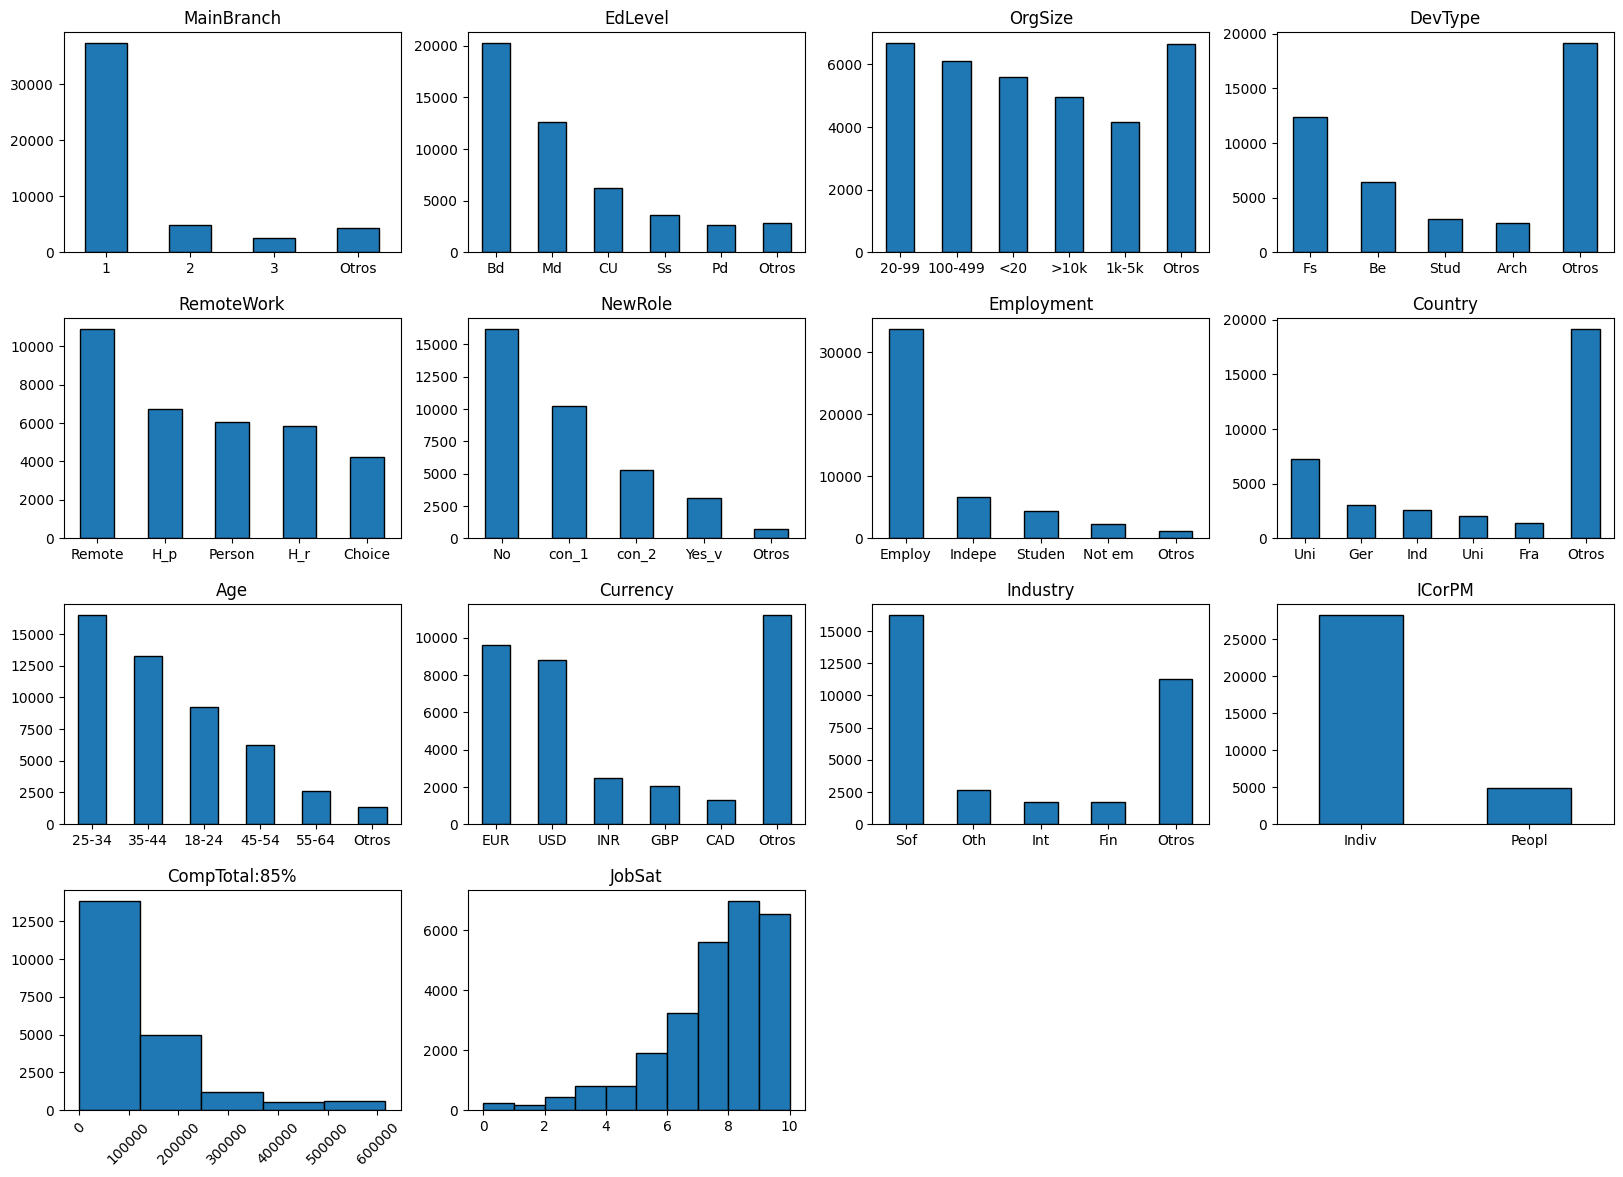

In [10]:
dash1.add.bar(df, "Country", min=1000, cut=3)
dash1.add.bar(df, "Age", min=2000, cut=' ')
dash1.add.bar(df, "Currency", min=1000, cut=3)
dash1.add.bar(df, "Industry", min=1500, cut=3)
dash1.add.bar(df, "ICorPM", min=1500, cut=5)
dash1.addChart(histEs(bins=5))
columnas1 = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole'
]
dash1.add.multiple_hist(df, columnas1, bins=10)

dash1.show()

<h4><u>Experencia y aprendizaje

In [11]:
dash2 = ds.Dashboard(columns=4, figsize=(20, 4))

In [12]:
columnas2 = [
    'WorkExp',
    'YearsCode',
    'LearnCodeChoose',
    'LearnCode',
    'LearnCodeAI',
    'AILearnHow',
]
dash2.add.multiple_hist(df, columnas2, bins=12)
maping_and_add('LearnCodeChoose', ['yes - master', 'no - master', 'yes = junr'], 0, dash2)
#maping_and_add('LearnCode', [], 0, dash2)
maping_and_add('LearnCodeAI', ['IA_Prof', 'IA_Pers', 'NoIA_Pers', 'No_learn', 'NoIA_Prof'], 0, dash2)
#maping_and_add('AILearnHow', [], 0, dash2)

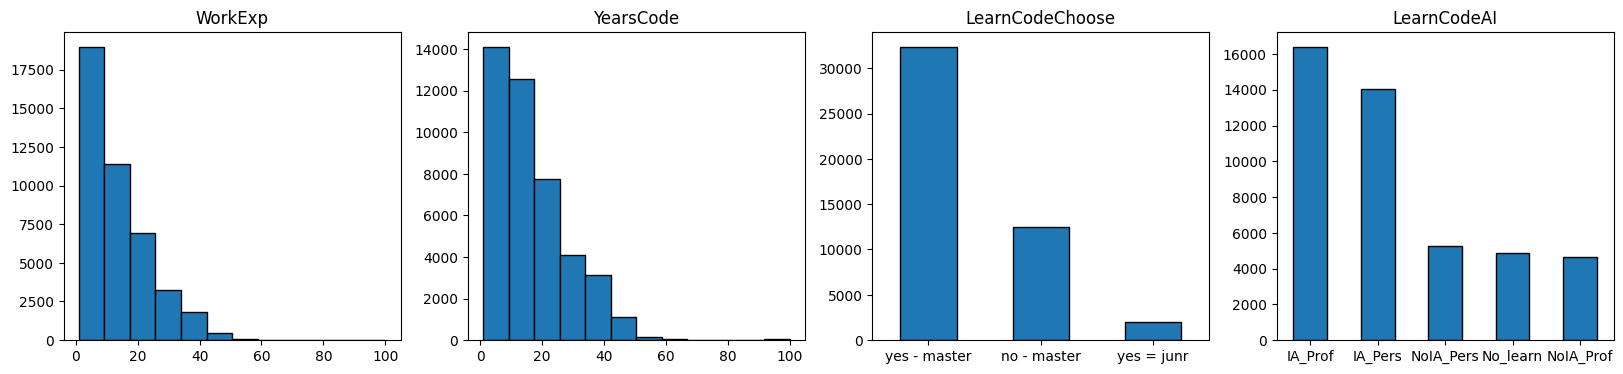

In [13]:
dash2.show()

<h4><u>Stack Tecnológico y Herramientas

In [14]:
dash3 = ds.Dashboard(columns=4, figsize=(20, 4))

In [15]:
def all_columns(df, start, values_change=[], min=0, ignored=None):
    sub = df.loc[:, df.columns.str.startswith(start)]
    for i in sub:
        if i != start + 'Choice' and (not ignored or i != start + ignored):
            maping_and_add(i, values_change, min, dash3, multiple=True)

In [16]:
columnas3 = [
    'LanguageChoice',
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LanguageAdmired',
    'DatabaseChoice',
    'DatabaseHaveWorkedWith',
    'DatabaseWantToWorkWith',
    'DatabaseAdmired',
    'PlatformChoice',
    'PlatformHaveWorkedWith',
    'PlatformWantToWorkWith',
    'PlatformAdmired',
    'WebframeChoice',
    'WebframeHaveWorkedWith',
    'WebframeWantToWorkWith',
    'WebframeAdmired',
    'DevEnvsChoice',
    'DevEnvsHaveWorkedWith',
    'DevEnvsWantToWorkWith',
    'DevEnvsAdmired',
    'OpSysPersonal use',
    'OpSysProfessional use',
    'OfficeStackAsyncHaveWorkedWith',
    'OfficeStackAsyncWantToWorkWith',
    'OfficeStackAsyncAdmired',
    'CommPlatformHaveWorkedWith',
    'CommPlatformWantToWorkWith',
    'CommPlatformAdmired',
    'AIModelsChoice',
    'AIModelsHaveWorkedWith',
    'AIModelsWantToWorkWith',
    'AIModelsAdmired',
]

In [17]:
dash3.add.bar(df, 'LanguageChoice', 0)
all_columns(df, 'Language', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 10000, 'Admired')
maping_and_add('LanguageAdmired', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 5000, dash3, multiple=True)

In [18]:
dash3.add.bar(df, 'DatabaseChoice', 0)
maping_and_add('DatabaseHaveWorkedWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 7000, dash3, multiple=True)
maping_and_add('DatabaseWantToWorkWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)
maping_and_add('DatabaseAdmired', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)

In [19]:
dash3.add.bar(df, 'PlatformChoice', 0)
maping_and_add('PlatformHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 6900, dash3, multiple=True)
maping_and_add('PlatformWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('PlatformAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)

In [20]:
dash3.add.bar(df, 'WebframeChoice', 0)
maping_and_add('WebframeHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 1000, dash3, multiple=True)

In [21]:
dash3.add.bar(df, 'DevEnvsChoice', 0)
maping_and_add('DevEnvsHaveWorkedWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsWantToWorkWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsAdmired', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 1000, dash3, multiple=True)

In [22]:
maping_and_add('OfficeStackAsyncHaveWorkedWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncWantToWorkWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncAdmired', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 1000, dash3, multiple=True)

In [23]:
maping_and_add('CommPlatformHaveWorkedWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformWantToWorkWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformAdmired', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 1000, dash3, multiple=True)

In [24]:
dash3.add.bar(df, 'AIModelsChoice', 0)
maping_and_add('AIModelsHaveWorkedWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsWantToWorkWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsAdmired', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 1000, dash3, multiple=True)

In [273]:
del dash3.charts[-4:]

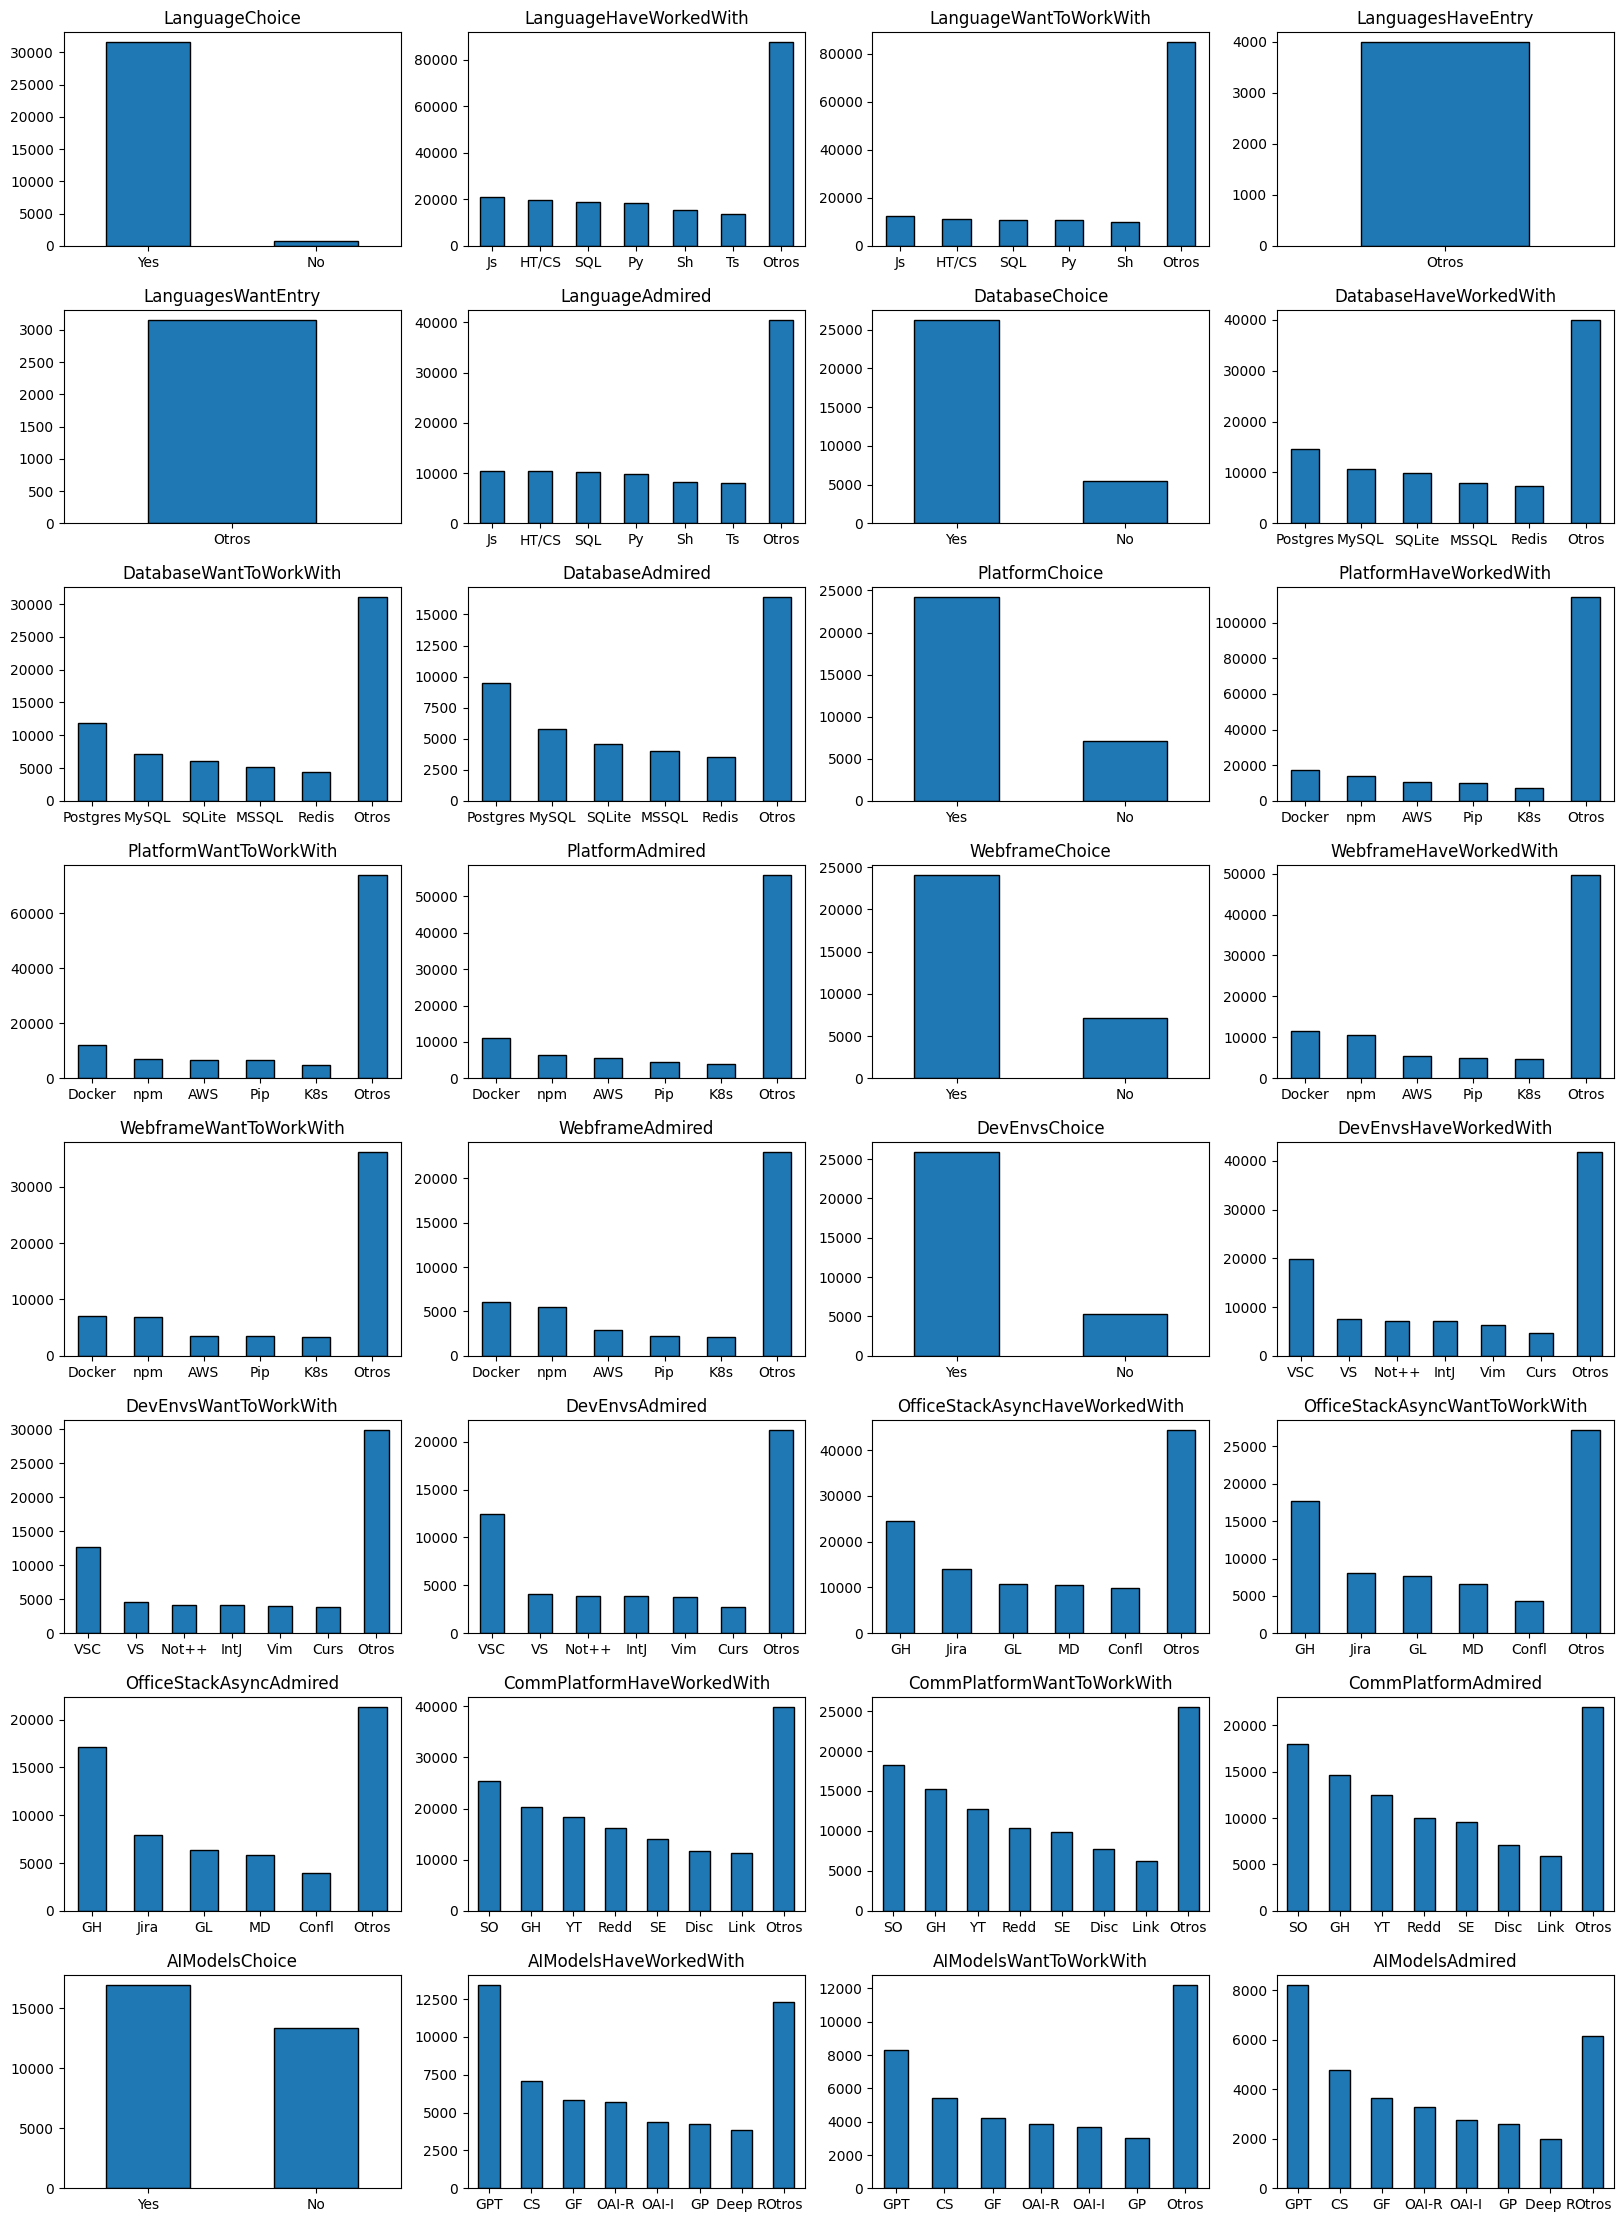

In [25]:
dash3.show()

<h3 style="color: violet;">Analisis de Outliers de variables numericas

<h4><u>CompTotal

Recordamos que un valor outlier es aquel que se encuentra por debajo de Q1 - 1.5 x IQR o por encima de Q3 + 1.5 x IQR

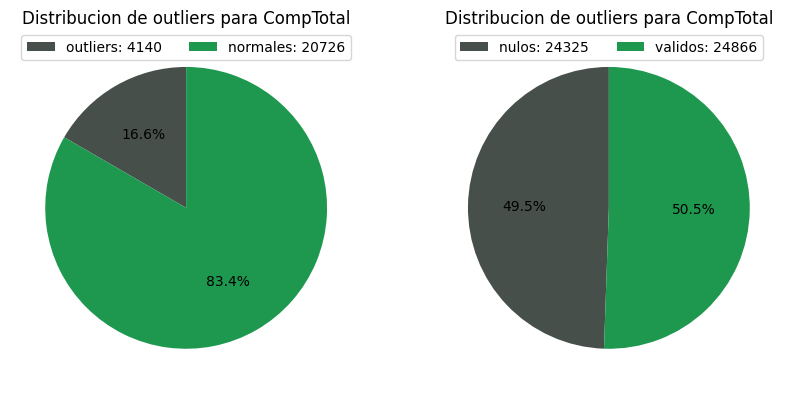

In [26]:
utils.graph_nulls_outliers(df, 'CompTotal')

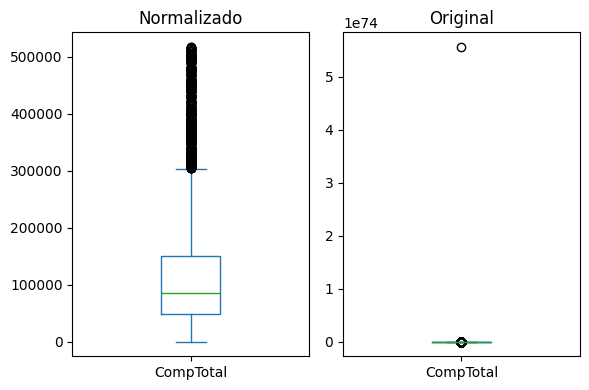

In [101]:
_, norm = utils.get_ranges(df, 'CompTotal')
_, ax = plt.subplots(1, 2, figsize=(6, 4))
norm['CompTotal'].plot(kind='box', ax=ax[0])
ax[0].set_xlim(0.7, 1.3)
ax[0].set_title('Normalizado')

df['CompTotal'].plot(kind='box', ax=ax[1])
ax[1].set_xlim(0.7, 1.3)
ax[1].set_title('Original')

plt.tight_layout()
plt.show()

<h4><u>WorkExp

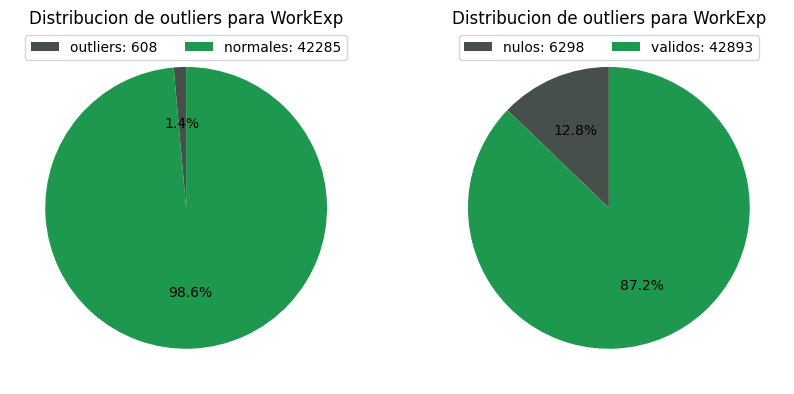

In [28]:
utils.graph_nulls_outliers(df, 'WorkExp')

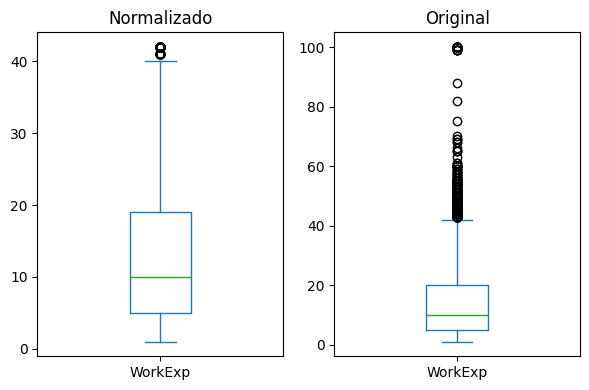

In [100]:
_, norm = utils.get_ranges(df, 'WorkExp')
_, ax = plt.subplots(1, 2, figsize=(6, 4))
norm['WorkExp'].plot(kind='box', ax=ax[0])
ax[0].set_xlim(0.7, 1.3)
ax[0].set_title('Normalizado')

df['WorkExp'].plot(kind='box', ax=ax[1])
ax[1].set_xlim(0.7, 1.3)
ax[1].set_title('Original')

plt.tight_layout()
plt.show()

<h4><u>yearCode

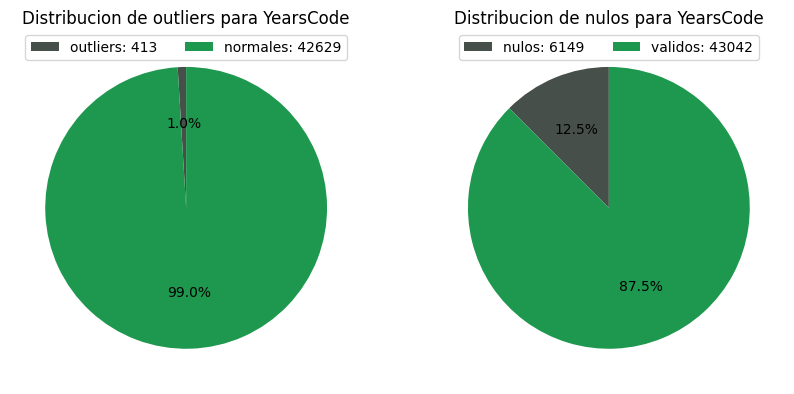

In [88]:
utils.graph_nulls_outliers(df, 'YearsCode')

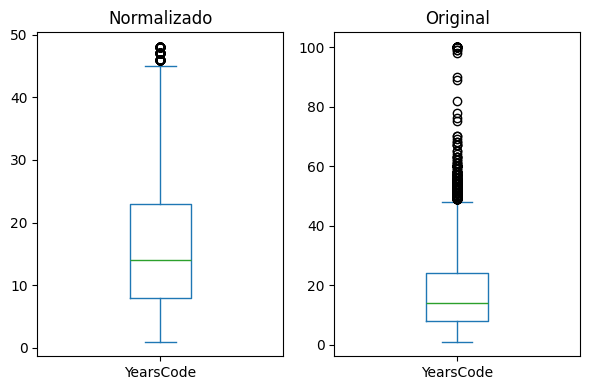

In [99]:
_, norm = utils.get_ranges(df, 'YearsCode')
_, ax = plt.subplots(1, 2, figsize=(6, 4))
norm['YearsCode'].plot(kind='box', ax=ax[0])
ax[0].set_xlim(0.7, 1.3)
ax[0].set_title('Normalizado')

df['YearsCode'].plot(kind='box', ax=ax[1])
ax[1].set_xlim(0.7, 1.3)
ax[1].set_title('Original')

plt.tight_layout()
plt.show()

<h3 style="color: violet;">Matriz de correlacion

Durante el analisis solo encontramos una relacion fuerte por encima del 0.6, tratandose del par (WorkExpr, YearsCode) teniendo sentido porque la gran mayoria crecen en ambos ejes a lo largo del tiempo.

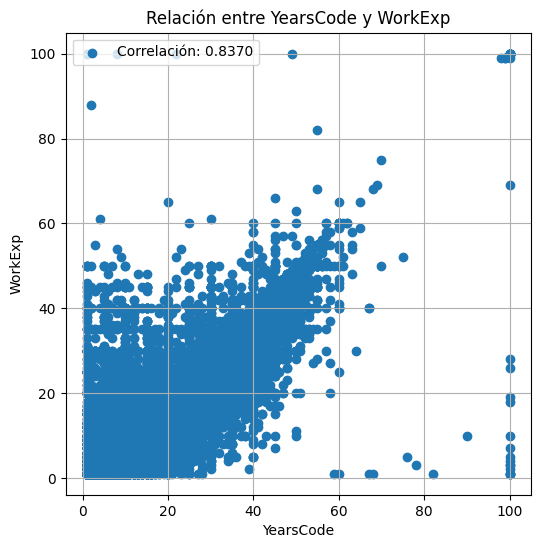

In [82]:
import re
correlation_matrix = df.corr(numeric_only=True)
corr_whithout_diag = correlation_matrix.mask(np.eye(len(correlation_matrix), dtype=bool))
cols = corr_whithout_diag.columns[corr_whithout_diag.abs().gt(0.6).any()]
correlation_matrix = correlation_matrix.loc[cols, cols]
correlation_matrix

,WorkExp,YearsCode
WorkExp,1.00000,0.83698
YearsCode,0.83698,1.00000


In [ ]:
utils.scatter('WorkExp', 'YearsCode', df)

In [ ]:
#df['ConvertedCompYearly'].value_counts()

<h1 style="color: orange;">Limpieza de datos

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [32]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [33]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

,qname,question,type,sub
10,TechEndorse_13_TEXT,What attracts you to a technology or causes yo...,RO,Other (please specify): - Text
21,TechOppose_15_TEXT,What would turn you off or cause you to reject...,RO,Other (please specify): - Text
37,JobSatPoints_15_TEXT,Rank the following attributes of your current ...,RO,Other (please specify): - Text
48,SO_Actions_15_TEXT,"When visiting Stack Overflow, which following ...",RO,Other (write in): - Text
77,LanguagesHaveEntry,Was the programming language you use not liste...,TE,NaN
78,LanguagesWantEntry,Was the programming language you want to use n...,TE,NaN


Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

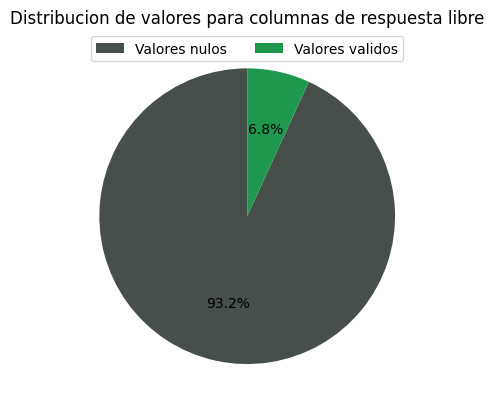

In [ ]:
datos = df[var_free['qname'].tolist()]
frecuencias = [
    #Promedio de promedios de cada columna.
    datos.isna().mean().mean(),
    datos.notna().mean().mean()
]
utils.pie_chart(
    df,
    frecuencias,
    labels=['Valores nulos', 'Valores validos'],
    title='Distribucion de valores para columnas de respuesta libre',
    colors=["#474f4a", '#1e984f']
)

In [35]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

Promedio: 0.93152710861743 - Cantidad nulos: 1283037 - Cantidad no nulos: 94311 - Total: 1377348


In [36]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [37]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
var_SO[['qname', 'question']].head(3)

,qname,question
38,SO_Actions_1,"When visiting Stack Overflow, which following ..."
39,SO_Actions_16,"When visiting Stack Overflow, which following ..."
40,SO_Actions_3,"When visiting Stack Overflow, which following ..."


In [38]:
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas a la influencia de compra tecnologica

In [18]:
df = df.drop(columns=['PurchaseInfluence', 'TechEndorseIntro'])

<h3 style="color: violet;">Reduccion por redundancia o por alto porcentaje de valores nulos

<h4><u>Registros duplicados

In [39]:
df = df.drop_duplicates()

<h4><u>ID de registros

In [40]:
df = df.drop(columns='ResponseId')

<h4><u>Variables no numericas con un porcentaje de valores nulos altos

Realizamos un analisis para identificar la distribucion de valores nulos en estas variables. Por estandar aplicado por nuestra decision, decidimos eliminar todas aquellas que tienen mas de un 80% de valores nulos en su conjunto.

In [43]:
percentages = df.isna().mean().sort_values(ascending=False)
drop_columns = percentages[percentages > 0.8].index.to_list()
df_80_nulls = pd.DataFrame({
    'Col': drop_columns
})
df_80_nulls

,Col
0,AIAgentObserveSecure
1,AIAgentKnowledge
2,AIAgentOrchestration
3,AIAgentImpactStrongly disagree
4,AIAgentImpactSomewhat disagree
5,AgentUsesGeneral
6,AIAgentImpactStrongly agree
7,AIAgentExternal
8,AIAgentChallengesStrongly disagree
9,AIAgentImpactNeutral


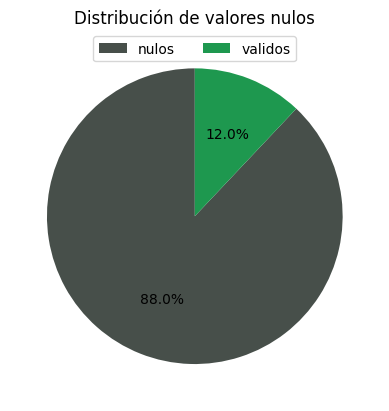

In [44]:
frecuencias = [df[drop_columns].isna().mean().mean(), df[drop_columns].notna().mean().mean()]
labels = ['nulos', 'validos']
utils.pie_chart(df, frecuencias, labels, colors=["#474f4a", '#1e984f'])

In [45]:
df = df.drop(columns=drop_columns)

In [ ]:
for i in df.columns:
    print(f"{i}: {df[i].value_counts()}")
    print("")

en el tema de anios de experecia laboral, algunos pusieron como 80 y pico de anios, no tiene sentido. Deberiamos sacar los outliers como metodo de limpieza?

dsp, en el tema de los roles, es como que el tema de analisis se repite un poco (VER VER)

dsp, en la cantidad de herramietas usadas, algunos superan los 100, no tiene sentido (sacar outliers?)

para el tema de la moneda hay que decidir con cual nos quedamos porque no hay forma de convertir todo a una sola sino (investigar variable conversion por anio)

preguntar si las de respuesta multiple habria que tener un explode